---
title: "Chapter 19 demo: Rain in Australia"
sidebar: demos
---

This walkthrough applies [Chapter 19](19_time-series.ipynb) to predicting whether it will rain tomorrow at Australian weather stations. We will compare a familiar classification pipeline with versions that include calendar and historical measurements.

Run the cells in order. Use the repository's `book/data/weatherAUS.csv`, from the Rain in Australia dataset used in the original lecture. If working outside the repository, place the CSV in a `data` folder beside this notebook.

In [1]:
#| code-fold: true
#| code-summary: "Show imports and setup"
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

DATA_DIR = Path("data") if Path("data").is_dir() else Path("book") / "data"

## Define the prediction task

At the end of each measurement day, predict `RainTomorrow` at the same location. We assume that day's listed measurements are available at this time. In deployment, publication delays and the exact observation windows would need checking.

The target is categorical, so we use classification. We predict one day at a time: measurements arrive between predictions, while the fitted model stays fixed during each validation period. This is different from predicting an entire month's rain at its beginning.

In [2]:
rain = pd.read_csv(DATA_DIR / "weatherAUS.csv", parse_dates=["Date"])
rain = rain.sort_values(["Location", "Date"]).reset_index(drop=True)
assert not rain.duplicated(["Location", "Date"]).any()
display(rain.head())
print("Locations:", rain["Location"].nunique())
print("Date range:", rain["Date"].min(), "to", rain["Date"].max())
display(rain.isna().mean().sort_values(ascending=False).head(8))

,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2008-07-01,Adelaide,8.8,15.7,5.0,1.6,2.6,NW,48.0,SW,...,92.0,67.0,1017.4,1017.7,NaN,NaN,13.5,14.9,Yes,No
1,2008-07-02,Adelaide,12.7,15.8,0.8,1.4,7.8,SW,35.0,SSW,...,75.0,52.0,1022.4,1022.6,NaN,NaN,13.7,15.5,No,No
2,2008-07-03,Adelaide,6.2,15.1,0.0,1.8,2.1,W,20.0,NNE,...,81.0,56.0,1027.8,1026.5,NaN,NaN,9.3,13.9,No,No
3,2008-07-04,Adelaide,5.3,15.9,0.0,1.4,8.0,NNE,30.0,NNE,...,71.0,46.0,1028.7,1025.6,NaN,NaN,10.2,15.3,No,No
4,2008-07-05,Adelaide,9.8,15.4,0.0,NaN,0.9,N,30.0,NNE,...,56.0,67.0,1023.6,1020.2,NaN,NaN,11.3,13.8,No,NaN


Locations: 49
Date range: 2007-11-01 00:00:00 to 2017-06-25 00:00:00


Sunshine       0.480098
Evaporation    0.431665
Cloud3pm       0.408071
Cloud9am       0.384216
Pressure9am    0.103568
Pressure3pm    0.103314
WindDir9am     0.072639
WindGustDir    0.070989
dtype: float64

## Inspect the time structure

How many series are present? There is a sequence of observations for each location. A shift across the whole dataframe could carry a measurement from one location into another.

Before constructing lags, also check whether consecutive rows within a location really represent consecutive days.

Date
1 days     145268
2 days          2
4 days          1
6 days          1
9 days          1
29 days        46
31 days        46
32 days        46
Name: Number of gaps, dtype: int64

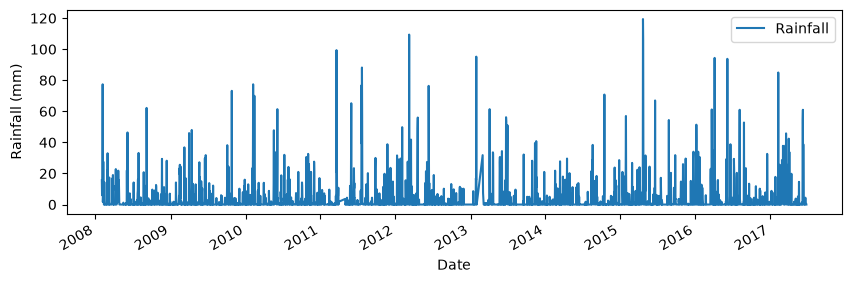

In [3]:
spacing = rain.groupby("Location")["Date"].diff()
display(spacing.value_counts().sort_index().rename("Number of gaps"))
sydney = rain.loc[rain["Location"].eq("Sydney")]
sydney.plot(x="Date", y="Rainfall", figsize=(10, 3), ylabel="Rainfall (mm)")
plt.show()

A previous observation is not always yesterday's observation. We will construct yesterday's measurement by matching the exact date and location. We do this before removing missing targets: a row without a target can still contain an observed measurement useful for the next day's prediction.

In [4]:
yesterday = rain[["Location", "Date", "Rainfall", "Humidity3pm"]].copy()
yesterday["Date"] = yesterday["Date"] + pd.Timedelta(days=1)
yesterday = yesterday.rename(columns={
    "Rainfall": "Rainfall_lag1day", "Humidity3pm": "Humidity3pm_lag1day"
})
rain = rain.merge(yesterday, on=["Location", "Date"], how="left", validate="one_to_one")
rain["Month"] = rain["Date"].dt.month_name()
rain = rain.dropna(subset=["RainTomorrow"]).copy()
display(rain[["Location", "Date", "Rainfall", "Rainfall_lag1day"]].head(10))

,Location,Date,Rainfall,Rainfall_lag1day
0,Adelaide,2008-07-01,5.0,NaN
1,Adelaide,2008-07-02,0.8,5.0
2,Adelaide,2008-07-03,0.0,0.8
3,Adelaide,2008-07-04,0.0,0.0
5,Adelaide,2008-07-06,NaN,0.0
6,Adelaide,2008-07-07,16.2,NaN
7,Adelaide,2008-07-08,17.0,16.2
8,Adelaide,2008-07-09,1.8,17.0
9,Adelaide,2008-07-10,9.0,1.8
12,Adelaide,2008-07-13,NaN,NaN


The merge uses only past measurements. If yesterday is missing, the lag remains missing; it does not silently substitute a measurement from several days ago. We will impute missing predictors inside each training fold.

## Establish a holdout and validation folds

Use observations through June 30, 2015 for development and later observations for a final holdout. How would ordinary `TimeSeriesSplit` behave if several rows share the same date?

Splitting rows can place different locations from the same date on opposite sides of a boundary. Instead, split unique dates, then map each date window back to rows. All locations on a date stay together. This evaluates future predictions at the locations represented in our data; it does not evaluate transfer to unseen locations.

In [5]:
cutoff = pd.Timestamp("2015-06-30")
train = rain.loc[rain["Date"] <= cutoff].sort_values(["Date", "Location"]).reset_index(drop=True)
test = rain.loc[rain["Date"] > cutoff].sort_values(["Date", "Location"]).reset_index(drop=True)
y_train, y_test = train["RainTomorrow"], test["RainTomorrow"]
dates = np.sort(train["Date"].unique())
folds = []
for fit_dates, valid_dates in TimeSeriesSplit(n_splits=3).split(dates):
    fit_rows = np.flatnonzero(train["Date"].isin(dates[fit_dates]))
    valid_rows = np.flatnonzero(train["Date"].isin(dates[valid_dates]))
    # RainTomorrow for date d is not known until the following day.
    # Leave a day between the last training feature date and validation origin.
    first_validation_date = train.iloc[valid_rows]["Date"].min()
    fit_rows = fit_rows[(train.iloc[fit_rows]["Date"] < first_validation_date - pd.Timedelta(days=1)).to_numpy()]
    assert train.iloc[fit_rows]["Date"].max() < first_validation_date - pd.Timedelta(days=1)
    folds.append((fit_rows, valid_rows))
    print(train.iloc[fit_rows]["Date"].max().date(), "→", first_validation_date.date())
# Apply the same conservative target-availability gap before the final holdout.
train = train.loc[train["Date"] < test["Date"].min() - pd.Timedelta(days=1)].copy()
y_train = train["RainTomorrow"]
# The removed rows are at the end, outside every fold's training/validation indices.
folds = [(a[a < len(train)], b[b < len(train)]) for a, b in folds]

2009-09-08 → 2009-09-10
2011-08-16 → 2011-08-18
2013-08-21 → 2013-08-23


The extra gap prevents training on tomorrow's outcome before it would be available. The exact gap should reflect the observation and publication schedule in the real application.

## Build a baseline and a familiar pipeline

Accuracy is easy to read, but predicting the majority class may look successful when most days are dry. We also report balanced accuracy, which averages recall for the two classes. Choose metrics based on the costs of missed rain and false alarms; neither metric alone describes every deployment concern.

In [6]:
numeric = [
    "MinTemp", "MaxTemp", "Rainfall", "Evaporation", "Sunshine",
    "WindGustSpeed", "WindSpeed9am", "WindSpeed3pm", "Humidity9am",
    "Humidity3pm", "Pressure9am", "Pressure3pm", "Cloud9am", "Cloud3pm",
    "Temp9am", "Temp3pm",
]
categorical = ["Location", "WindGustDir", "WindDir9am", "WindDir3pm", "RainToday"]

def make_rain_model(extra_numeric=(), extra_categorical=()):
    preprocessing = ColumnTransformer([
        ("numeric", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()),
         numeric + list(extra_numeric)),
        ("categorical", make_pipeline(
            SimpleImputer(strategy="constant", fill_value="missing"),
            OneHotEncoder(handle_unknown="ignore")),
         categorical + list(extra_categorical)),
    ])
    return make_pipeline(preprocessing, LogisticRegression(max_iter=1000))

models = {
    "Majority baseline": DummyClassifier(strategy="most_frequent"),
    "Measurements": make_rain_model(),
    "Measurements + month": make_rain_model(extra_categorical=["Month"]),
    "Measurements + month + lags": make_rain_model(
        extra_numeric=["Rainfall_lag1day", "Humidity3pm_lag1day"],
        extra_categorical=["Month"]),
}
results = {}
for name, model in models.items():
    # DummyClassifier needs no raw date/string columns.
    X = train[["Rainfall"]] if name == "Majority baseline" else train
    results[name] = cross_val_score(
        model, X, y_train, cv=folds, scoring="balanced_accuracy"
    )
validation = pd.DataFrame(results, index=["Fold 1", "Fold 2", "Fold 3"]).T
validation["Mean"] = validation.mean(axis=1)
display(validation)

,Fold 1,Fold 2,Fold 3,Mean
Majority baseline,0.500000,0.500000,0.500000,0.500000
Measurements,0.736879,0.722298,0.729205,0.729461
Measurements + month,0.742480,0.722717,0.730469,0.731889
Measurements + month + lags,0.743148,0.724828,0.731552,0.733176


## Interpret the feature comparisons

Month is known in advance and may capture seasonal differences. We encode it categorically rather than imposing a linear increase from January to December. Location lets one model use data across stations, although this additive logistic model does not automatically learn location-specific seasonal effects.

Lag features provide yesterday's measurements, while today's rainfall and humidity are already present. The lags may add little once current measurements are included. Their usefulness is an empirical question, not a guarantee.

::: {.callout-note}
### Pause and discuss

- Do the feature additions improve every validation fold, or only the average?
- Would yesterday's observed humidity remain available if we forecast an entire month in advance?
- Why would grouping by location before `shift(1)` still be insufficient to guarantee a one-day lag?

Grouping prevents crossing locations, but only a date check or an exact date match establishes the elapsed interval. Observed future-period measurements are available in this repeated one-day setup, not for a whole month forecast at once.
:::

## Evaluate the selected approach

Select using validation balanced accuracy, then inspect the final holdout once. Small validation differences may be unstable; simplicity and consistency across periods matter too.

In [7]:
best_name = validation["Mean"].idxmax()
selected = models[best_name]
X_train = train[["Rainfall"]] if best_name == "Majority baseline" else train
X_test = test[["Rainfall"]] if best_name == "Majority baseline" else test
selected.fit(X_train, y_train)
predictions = selected.predict(X_test)
print("Selected:", best_name)
print(f"Holdout accuracy: {accuracy_score(y_test, predictions):.3f}")
print(f"Holdout balanced accuracy: {balanced_accuracy_score(y_test, predictions):.3f}")

Selected: Measurements + month + lags
Holdout accuracy: 0.846
Holdout balanced accuracy: 0.713


This estimate describes future dates at the observed locations under our information-availability assumptions. A different forecast horizon, a new location, or a change in measurement practices would require a different evaluation design.

The main adaptations were to define the prediction timing, split by dates, account for target availability, and match lag measurements within location by elapsed time. The classification pipeline itself remained familiar.